# Module 1 · Partie 5 : Estimation numérique des coefficients (descente de gradient)

> Sources de cette partie : syllabus `module1.pdf` §3.5 *Numerical estimation of coefficients* (Fig. 7 à 11, d'après Andrew Ng), slides *Linear, Ridge, Lasso regressions* (« Estimation of regression coefficients by iteration », « Gradient descent »).

**Objectifs d'apprentissage**

À la fin de ce notebook, tu sauras :

1. définir la **fonction de coût** $J(\beta)$ d'une régression linéaire et la représenter (courbe à 1 paramètre, surface 3D et courbes de niveau à 2 paramètres) ;
2. calculer les **dérivées partielles** de $J$ et expliquer le principe de la **descente de gradient** (*gradient descent*) ;
3. programmer l'algorithme en R, avec mise à jour **simultanée** des coefficients ;
4. comprendre le rôle du **taux d'apprentissage** $\alpha$ (*learning rate*) et vérifier la **convergence** ;
5. justifier la **mise à l'échelle des variables** (*feature scaling*) pour accélérer l'algorithme ;
6. **généraliser** l'algorithme à $p$ variables sous forme matricielle et le comparer à `lm()`.

**Prérequis** : partie 2 (moindres carrés, $a = \bar y - b\bar x$, $b = cov(x,y)/s_x^2$), partie 3 (forme matricielle $y = X\beta + e$, $\hat\beta = (X'X)^{-1}X'y$).

**Sommaire**

- 5.0 Mise en place
- 5.1 Pourquoi une estimation numérique ?
- 5.2 Fonction de coût à un paramètre : $J(\beta_1)$
- 5.3 Fonction de coût à deux paramètres : $J(\beta_0, \beta_1)$
- 5.4 Dérivées partielles et descente de gradient
- 5.5 Le taux d'apprentissage $\alpha$
- 5.6 Vérifier la convergence
- 5.7 Mise à l'échelle des variables (feature scaling)
- 5.8 Généralisation : descente de gradient multivariée
- 5.9 Complément : `optim()`
- Récapitulatif

## 5.0 Mise en place

On reprend l'exemple fil rouge : la teneur en lactoferrine (en **log10**, cf. partie 2) expliquée par le point spectral **V713**, le plus corrélé. Par moindres carrés, la partie 2 donnait : $\widehat{\log_{10}(y)} = 3.150 + 6.373\,x$.

In [1]:
options(repr.plot.width = 10, repr.plot.height = 6)   # taille des figures (propre à Jupyter)

lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
x  <- lactoferrin$V713              # point spectral le plus corrélé (absorbance)
ly <- log10(lactoferrin$V1062)      # log10 de la lactoferrine
n  <- length(ly)

summary(x); sd(x)
coef(lm(ly ~ x))                    # solution analytique (référence)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.26017 -0.20657 -0.18777 -0.17733 -0.13837 -0.07039 

[1] 0.04114965

(Intercept)           x 
   3.150178    6.373433

Remarque déjà importante pour la suite : l'absorbance `x` varie dans un intervalle **minuscule** (de −0.26 à −0.07, écart-type 0.04), alors que l'intercept vaut environ 3. Les deux coefficients sont à des **échelles très différentes** : on verra en 5.7 que cela gêne fortement l'algorithme.

## 5.1 Pourquoi une estimation numérique ?

On a vu deux façons **analytiques** (exactes, par une formule) d'obtenir les coefficients :

- univarié : $b = \dfrac{cov(x,y)}{s_x^2}$, $a = \bar y - b\bar x$ (équations normales) ;
- multivarié : $\hat\beta = (X'X)^{-1}X'y$ (moindres carrés ordinaires, OLS).

Mais, comme le dit la slide, **« l'inversion peut parfois être problématique »** :

- si les variables sont **colinéaires**, $X'X$ est (presque) **singulière** → inversion impossible ou très instable ;
- si le nombre de variables est **très grand**, inverser une matrice $p \times p$ coûte cher ;
- pour beaucoup d'autres modèles de Machine Learning (régression logistique, réseaux de neurones…), **il n'existe pas de formule fermée**.

On cherche alors les coefficients **numériquement**, par **itérations** : on part de valeurs initiales et on les améliore pas à pas jusqu'à atteindre le minimum de l'erreur. C'est le principe de la **descente de gradient**, à la base de nombreux algorithmes de ML (notamment les réseaux de neurones du module 6).

## 5.2 Fonction de coût à un paramètre : $J(\beta_1)$

Le syllabus part d'une régression **avec un seul coefficient et sans intercept** ($a = 0$) :

$$y = \beta_1 x + e$$

Trouver $\beta_1$, c'est **minimiser l'erreur quadratique moyenne** (MSE). Vue comme une fonction de $\beta_1$, on l'appelle **fonction de coût** (*cost function*) :

$$J(\beta_1) = e^2 = \frac{1}{n}\sum_{i=1}^{n}(y_i - \beta_1 x_i)^2$$

> **Définition** : la **fonction de coût** $J$ mesure l'erreur du modèle pour une valeur donnée des coefficients. La **meilleure estimation** des coefficients est celle qui **minimise** $J$ (Fig. 7 du syllabus).

Pour pouvoir travailler sans intercept, on **centre** $x$ et $y$ (on leur retire leur moyenne) : la droite des moindres carrés passe alors par l'origine.

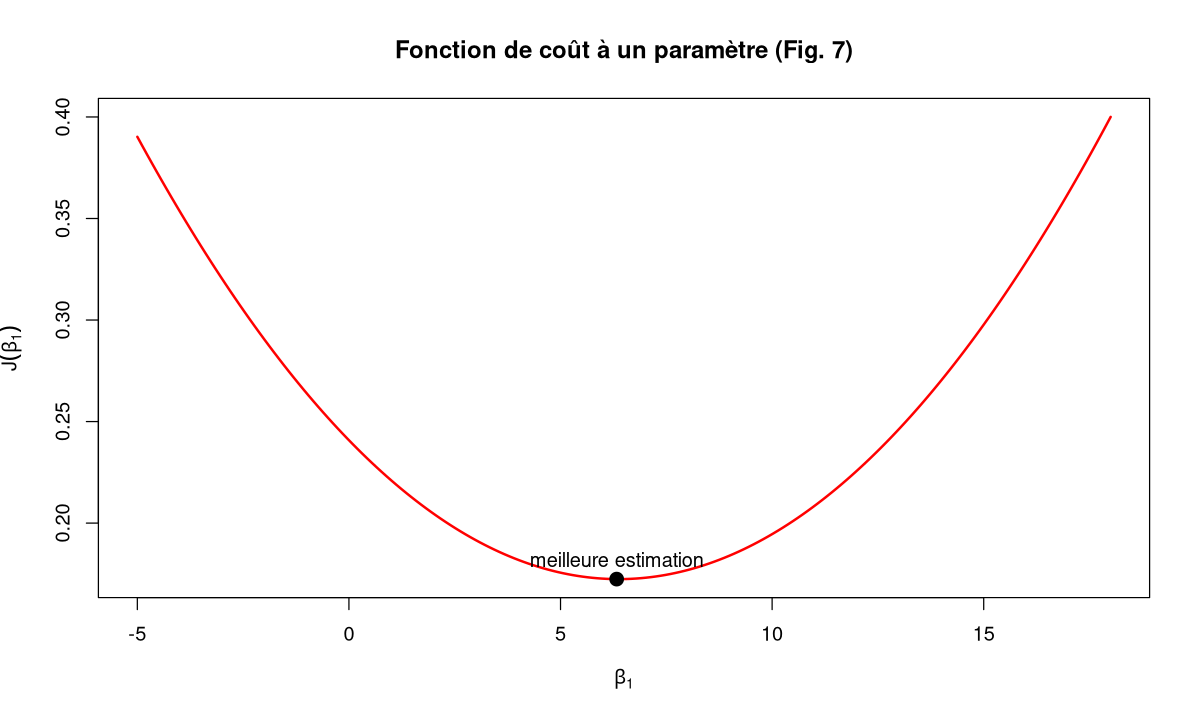

In [2]:
xc <- x - mean(x)          # x centré
yc <- ly - mean(ly)        # y centré

J1 <- function(b1) mean((yc - b1 * xc)^2)    # fonction de coût à 1 paramètre

beta1_grid <- seq(-5, 18, length.out = 200)  # valeurs candidates de beta1
J_grid <- sapply(beta1_grid, J1)             # J pour chacune

plot(beta1_grid, J_grid, type = "l", lwd = 2, col = "red",
     xlab = expression(beta[1]), ylab = expression(J(beta[1])),
     main = "Fonction de coût à un paramètre (Fig. 7)")
b1_best <- beta1_grid[which.min(J_grid)]
points(b1_best, min(J_grid), pch = 19, cex = 1.5)
text(b1_best, min(J_grid), "meilleure estimation", pos = 3)

La fonction de coût est une **parabole** (polynôme du 2e degré en $\beta_1$) : elle a **un seul minimum**, ce qui garantit qu'un algorithme qui « descend » finira par le trouver.

Pour des données **centrées**, la slide indique le résultat analytique après standardisation : $\beta_1 = \dfrac{\sum xy}{\sum x^2}$. Vérifions :

In [3]:
b1_grid_min <- b1_best                     # minimum trouvé "à l'œil" sur la grille
b1_formule  <- sum(xc * yc) / sum(xc^2)    # formule de la slide (données centrées)
c(grille = b1_grid_min, formule = b1_formule, lm = unname(coef(lm(ly ~ x))[2]))

grille  formule       lm 
6.326633 6.373433 6.373433

La recherche sur une grille donne une valeur approchée (sa précision dépend du pas de la grille) ; la formule et `lm()` donnent exactement **6.373**.

> **Attention** : une recherche sur grille est simple mais **inefficace** : avec 2 paramètres et 200 valeurs chacun, il faut 40 000 évaluations ; avec 10 paramètres, $200^{10}$ ! D'où l'intérêt d'un algorithme qui **se dirige** vers le minimum : la descente de gradient.

### Exercice 5.1 : évaluer la fonction de coût

1. Calcule $J(0)$, $J(6.373)$ et $J(12)$. Lequel est le plus petit ?
2. Montre que $J(0)$ est égal à la variance de `yc` calculée avec un dénominateur $n$ (et non $n-1$). Pourquoi est-ce logique ?

In [4]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
J1(0); J1(6.373); J1(12)          # J(6.373) est le plus petit (c'est le minimum)
J1(0)
mean(yc^2)                        # variance "en 1/n" de yc
var(yc) * (n - 1) / n             # même chose à partir de var() (qui divise par n-1)
```

Avec $\beta_1 = 0$, le modèle prédit 0 (la moyenne, puisque y est centré) pour tout le monde : l'erreur quadratique moyenne est alors la **variance de y**. C'est le lien vu en partie 2 : $MSE = s_y^2(1-r^2)$, qui vaut $s_y^2$ quand le modèle n'explique rien.

</details>

## 5.3 Fonction de coût à deux paramètres : $J(\beta_0, \beta_1)$

Avec un intercept, la régression devient $y = \beta_0 + \beta_1 x + e$ et la fonction de coût dépend de **deux** paramètres :

$$J(\beta_0,\beta_1) = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \beta_0 - \beta_1 x_i\right)^2$$

On n'a plus une courbe mais une **surface en 3 dimensions** (Fig. 8 du syllabus), en forme de « bol ». Pour la visualiser proprement, on met d'abord `x` à l'échelle **min-max** (entre 0 et 1 ; c'est une des méthodes de *feature scaling* vues en 5.7).

(Intercept)          xm 
   1.491970    1.209576

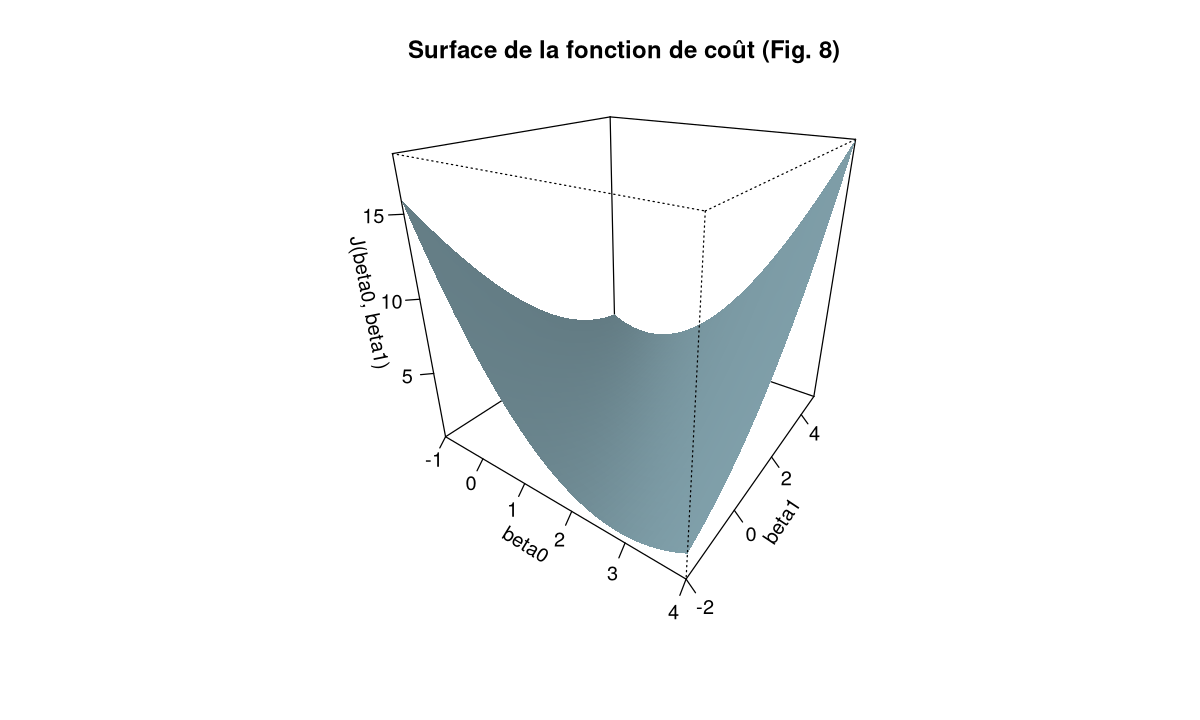

In [5]:
xm <- (x - min(x)) / (max(x) - min(x))      # x mis à l'échelle min-max (0 <= xm <= 1)
coef(lm(ly ~ xm))                            # minimum exact à retrouver

J2 <- function(b0, b1) mean((ly - b0 - b1 * xm)^2)   # fonction de coût à 2 paramètres

b0_seq <- seq(-1, 4, length.out = 60)
b1_seq <- seq(-2, 5, length.out = 60)
Jmat <- outer(b0_seq, b1_seq, Vectorize(J2))  # matrice des valeurs de J sur la grille

persp(b0_seq, b1_seq, Jmat, theta = 35, phi = 25, col = "lightblue", border = NA,
      shade = 0.6, ticktype = "detailed",
      xlab = "beta0", ylab = "beta1", zlab = "J(beta0, beta1)",
      main = "Surface de la fonction de coût (Fig. 8)")

La surface en 3D est difficile à lire. On la représente plutôt par ses **courbes de niveau** (Fig. 10 du syllabus) : c'est une **coupe** de la surface ; chaque courbe relie les points $(\beta_0, \beta_1)$ qui ont **la même valeur** de $J$. Les couleurs froides (bleu) correspondent aux plus faibles valeurs de $J$, donc au voisinage du minimum.

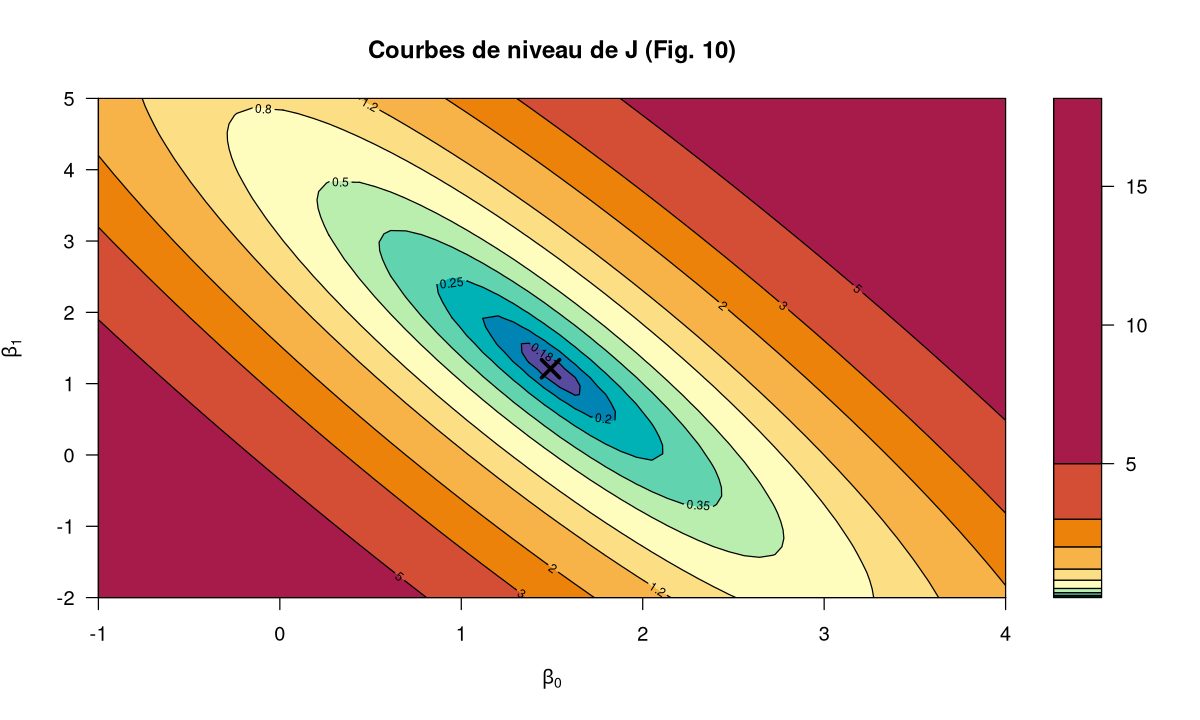

In [6]:
niveaux <- c(0.18, 0.2, 0.25, 0.35, 0.5, 0.8, 1.2, 2, 3, 5)
filled.contour(b0_seq, b1_seq, Jmat, levels = c(0.17, niveaux, max(Jmat)),
               color.palette = function(k) hcl.colors(k, "Spectral", rev = TRUE),
               xlab = expression(beta[0]), ylab = expression(beta[1]),
               main = "Courbes de niveau de J (Fig. 10)",
               plot.axes = { axis(1); axis(2)
                 contour(b0_seq, b1_seq, Jmat, levels = niveaux, add = TRUE)
                 points(coef(lm(ly ~ xm))[1], coef(lm(ly ~ xm))[2], pch = 4, cex = 2, lwd = 3) })

Les courbes de niveau sont des **ellipses** inclinées autour du minimum (la croix). L'inclinaison vient du fait que $\beta_0$ et $\beta_1$ ne sont pas indépendants : si on augmente la pente, il faut diminuer l'intercept pour rester proche des données.

> **Fonctions R graphiques pour les surfaces**
>
> | Fonction | Rôle | Arguments clés |
> |---|---|---|
> | `outer(X, Y, FUN)` | évalue `FUN(x, y)` pour toutes les combinaisons → matrice | `FUN` doit être **vectorisée** : d'où `Vectorize(J2)` |
> | `persp(x, y, z, theta, phi)` | surface 3D en perspective | `theta`/`phi` = angles de vue, `col`, `shade`, `ticktype` |
> | `contour(x, y, z, levels, add)` | courbes de niveau | `levels` = valeurs des courbes ; `add = TRUE` pour superposer |
> | `filled.contour(x, y, z, ...)` | courbes de niveau colorées + légende | `color.palette`, `plot.axes = {...}` pour ajouter des éléments |
>
> **Généralisation** : pour visualiser n'importe quelle fonction de 2 variables `f(a, b)`, on crée deux grilles `seq()`, on calcule `z <- outer(a_seq, b_seq, Vectorize(f))` et on trace `contour()` ou `persp()`.

## 5.4 Dérivées partielles et descente de gradient

### L'idée

Imagine que tu es sur la surface de $J$ dans le brouillard et que tu veux descendre au fond du bol : à chaque pas, tu regardes **la pente sous tes pieds** et tu fais un pas **dans le sens de la descente**. La pente est donnée par la **dérivée** (le **gradient** quand il y a plusieurs paramètres).

- Si la dérivée est **positive**, $J$ augmente quand $\beta$ augmente → il faut **diminuer** $\beta$.
- Si la dérivée est **négative** → il faut **augmenter** $\beta$.
- **Plus on est loin du meilleur estimateur, plus la dérivée (= la pente) est grande** (slide) → les pas sont grands loin du minimum et deviennent petits près du minimum.

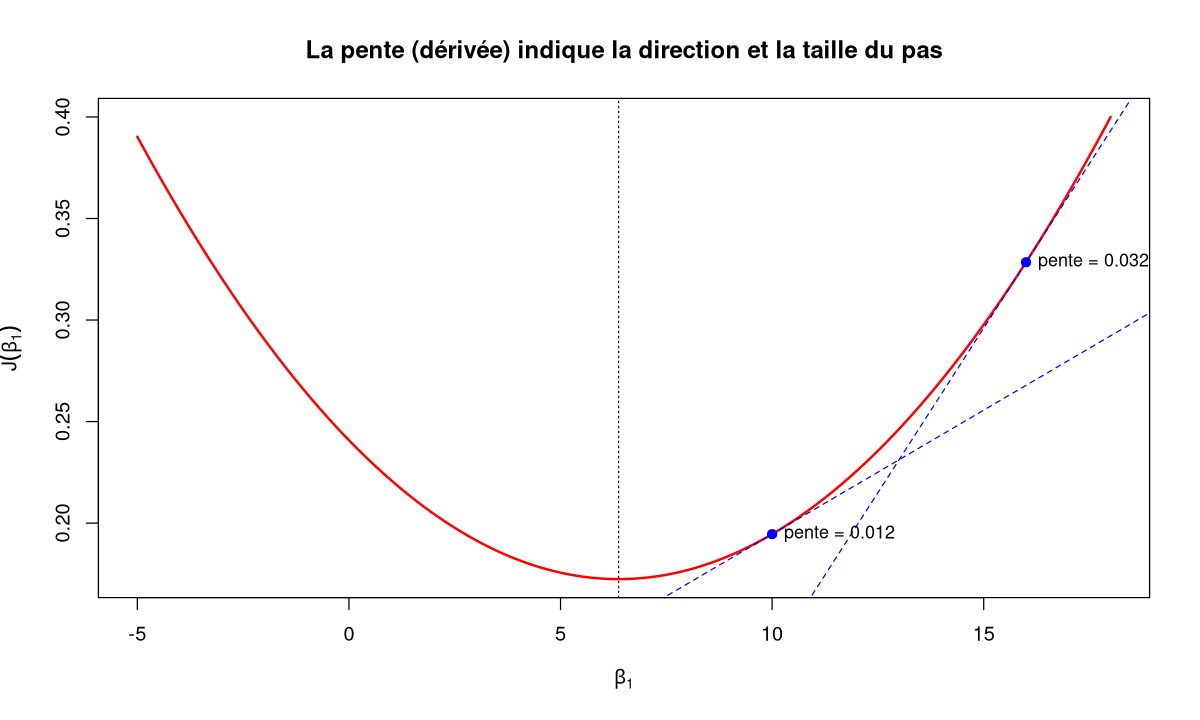

In [7]:
# Illustration (Fig. 9) : pente de J(beta1) en deux points
dJ1 <- function(b1) -2 * mean(xc * (yc - b1 * xc))       # dérivée de J(beta1)
plot(beta1_grid, J_grid, type = "l", lwd = 2, col = "red",
     xlab = expression(beta[1]), ylab = expression(J(beta[1])),
     main = "La pente (dérivée) indique la direction et la taille du pas")
for (b in c(16, 10)) {
  pente <- dJ1(b)
  abline(a = J1(b) - pente * b, b = pente, col = "blue", lty = 2)   # tangente en b
  points(b, J1(b), pch = 19, col = "blue")
  text(b, J1(b), paste0("pente = ", signif(pente, 2)), pos = 4, cex = 0.9)
}
abline(v = b1_formule, lty = 3)

Au point $\beta_1 = 16$ (loin du minimum), la pente est plus forte qu'en $\beta_1 = 10$ (plus près). Dans les deux cas elle est positive → on doit diminuer $\beta_1$.

### Les formules

Pour $J(\beta_0,\beta_1) = \frac{1}{n}\sum (y_i - \beta_0 - \beta_1 x_i)^2$, les **dérivées partielles** sont :

$$\frac{\partial}{\partial\beta_0}J(\beta_0,\beta_1) = -\frac{2}{n}\sum_{i=1}^{n}\left(y_i - \beta_0 - \beta_1 x_i\right)
\qquad
\frac{\partial}{\partial\beta_1}J(\beta_0,\beta_1) = -\frac{2}{n}\sum_{i=1}^{n}x_i\left(y_i - \beta_0 - \beta_1 x_i\right)$$

(on reconnaît, au facteur près, les **équations normales** de la partie 2 : au minimum, ces dérivées valent 0).

À chaque **itération**, l'algorithme met à jour **simultanément** les deux coefficients (syllabus §3.5) :

$$temp_0 = \beta_0 - \alpha\,\frac{\partial}{\partial\beta_0}J(\beta_0,\beta_1) \qquad temp_1 = \beta_1 - \alpha\,\frac{\partial}{\partial\beta_1}J(\beta_0,\beta_1)$$
$$\beta_0 = temp_0 \qquad \beta_1 = temp_1$$

- $\alpha$ est le **taux d'apprentissage** (*learning rate*) : la taille de l'incrément ;
- les valeurs de départ sont appelées **valeurs initiales** (*priors*) ;
- la **convergence** est atteinte quand une nouvelle mise à jour ne fait plus diminuer $J$.

> **Attention : mise à jour simultanée.** Les variables `temp0` et `temp1` servent à calculer **les deux** dérivées avec les **anciennes** valeurs de $\beta_0$ et $\beta_1$. Si on mettait à jour $\beta_0$ puis on calculait la dérivée en $\beta_1$ avec le nouveau $\beta_0$, ce ne serait plus une descente de gradient.

> **Complément** : dans le cours d'Andrew Ng (dont viennent les figures 9 à 11), la fonction de coût est définie avec $\frac{1}{2n}$ au lieu de $\frac{1}{n}$ pour que le « 2 » de la dérivée disparaisse. Ça ne change pas le minimum, seulement l'échelle de $\alpha$.

### Quelques itérations « à la main »

In [8]:
alpha <- 0.5                 # taux d'apprentissage
beta0 <- 0; beta1 <- 0       # valeurs initiales (priors)

for (iter in 1:3) {
  residus <- ly - beta0 - beta1 * xm              # résidus avec les coefficients ACTUELS
  d0 <- -2 * mean(residus)                        # dérivée partielle par rapport à beta0
  d1 <- -2 * mean(xm * residus)                   # dérivée partielle par rapport à beta1
  temp0 <- beta0 - alpha * d0                     # mises à jour simultanées
  temp1 <- beta1 - alpha * d1
  beta0 <- temp0; beta1 <- temp1
  cat("Itération", iter, ": beta0 =", round(beta0, 4), " beta1 =", round(beta1, 4),
      " J =", round(J2(beta0, beta1), 4), "\n")
}

Itération 1 : beta0 = 2.02  beta1 = 0.9384  J = 0.3437 
Itération 2 : beta0 = 1.6104  beta1 = 0.7722  J = 0.1866 
Itération 3 : beta0 = 1.6829  beta1 = 0.8243  J = 0.1799 


À chaque itération, $J$ diminue. Il reste à **répéter** jusqu'à la convergence. On écrit pour cela une fonction réutilisable :

In [9]:
descente_gradient_2p <- function(x, y, alpha, n_iter = 10000, b_init = c(0, 0), tol = 1e-12) {
  b <- b_init
  J <- numeric(n_iter)                    # historique de la fonction de coût
  chemin <- matrix(NA, n_iter, 2)         # historique des coefficients
  for (i in 1:n_iter) {
    r <- y - b[1] - b[2] * x              # résidus
    J[i] <- mean(r^2)
    chemin[i, ] <- b
    grad <- c(-2 * mean(r), -2 * mean(x * r))
    b <- b - alpha * grad                 # mise à jour simultanée (vecteur)
    if (!is.finite(J[i])) break           # divergence : on arrête
    if (i > 1 && abs(J[i - 1] - J[i]) < tol) break   # convergence : J ne diminue plus
  }
  list(coef = b, J = J[1:i], chemin = chemin[1:i, , drop = FALSE], iterations = i)
}

gd <- descente_gradient_2p(xm, ly, alpha = 0.5)
gd$iterations
rbind(descente_gradient = gd$coef, lm = coef(lm(ly ~ xm)))

[1] 258

,(Intercept),xm
descente_gradient,1.491977,1.209560
lm,1.491970,1.209576


La descente de gradient retrouve les coefficients de `lm()` (à $10^{-4}$ près, selon la tolérance choisie) en environ 250 itérations.

Visualisons le **chemin** parcouru sur les courbes de niveau (comme la Fig. 10) :

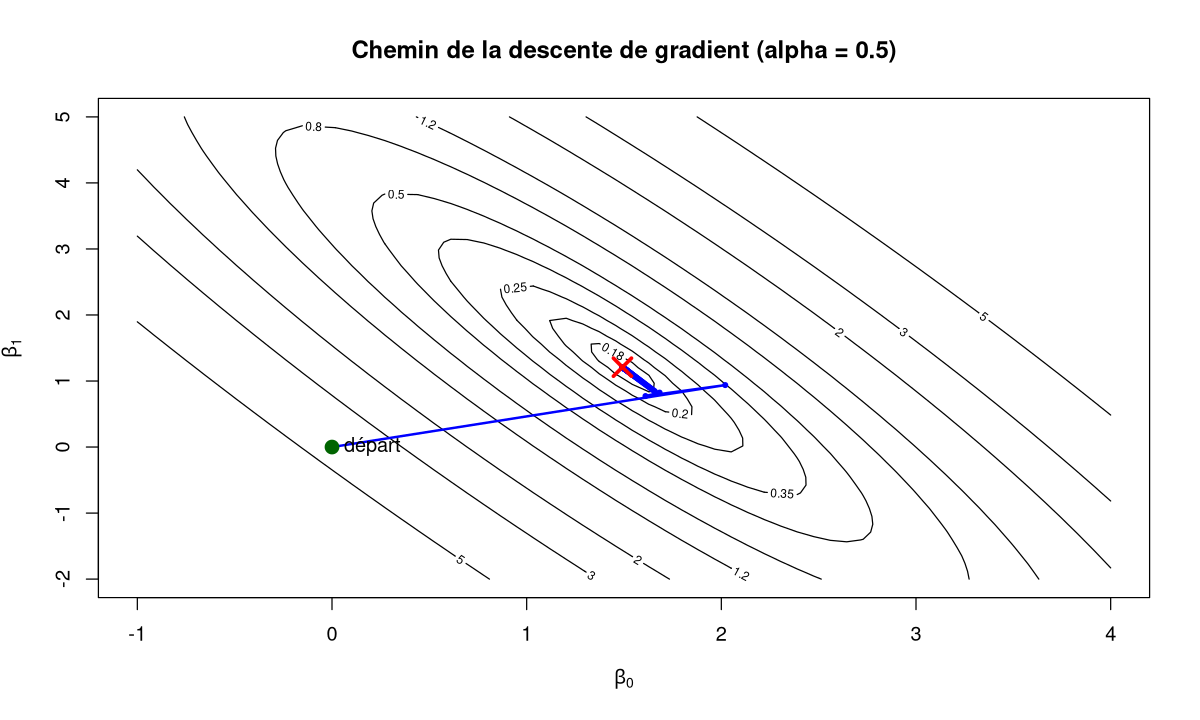

In [10]:
contour(b0_seq, b1_seq, Jmat, levels = niveaux, xlab = expression(beta[0]),
        ylab = expression(beta[1]), main = "Chemin de la descente de gradient (alpha = 0.5)")
lines(gd$chemin[, 1], gd$chemin[, 2], col = "blue", lwd = 2, type = "o", pch = 20, cex = 0.6)
points(0, 0, pch = 19, col = "darkgreen", cex = 1.5); text(0, 0, "départ", pos = 4)
points(gd$coef[1], gd$coef[2], pch = 4, col = "red", cex = 2, lwd = 3)

Le chemin part de (0, 0), fait de **grands pas** au début (pente forte) puis des **petits pas** en approchant du minimum (pente faible), exactement comme décrit dans le syllabus : *« un pas plus petit sera fait près du minimum car la dérivée partielle sera plus petite. Il n'est donc pas nécessaire de modifier α au cours des itérations. »*

### Exercice 5.2 : changer les valeurs initiales

Relance `descente_gradient_2p()` avec les valeurs initiales `b_init = c(3, -1)` puis `c(-1, 5)`. Le résultat final change-t-il ? Et le nombre d'itérations ? Trace les deux chemins sur le même graphe de contours.

In [11]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
gdA <- descente_gradient_2p(xm, ly, alpha = 0.5, b_init = c(3, -1))
gdB <- descente_gradient_2p(xm, ly, alpha = 0.5, b_init = c(-1, 5))
rbind(A = c(gdA$coef, gdA$iterations), B = c(gdB$coef, gdB$iterations))

contour(b0_seq, b1_seq, Jmat, levels = niveaux)
lines(gdA$chemin, col = "blue", type = "o", pch = 20, cex = 0.5)
lines(gdB$chemin, col = "purple", type = "o", pch = 20, cex = 0.5)
```

Les deux départs aboutissent au **même minimum** (la fonction de coût d'une régression linéaire est convexe : un seul minimum). En revanche, le **nombre d'itérations** dépend des valeurs initiales : *« la vitesse d'estimation dépend des valeurs initiales (priors) et du taux d'apprentissage »* (syllabus).

</details>

### Exercice 5.3 : mise à jour NON simultanée (erreur classique)

Modifie la boucle « à la main » ci-dessus pour mettre à jour `beta0` **avant** de calculer la dérivée en `beta1` (sans `temp0`/`temp1`). Fais 3 itérations et compare les valeurs obtenues avec celles de la version correcte.

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
alpha <- 0.5; beta0 <- 0; beta1 <- 0
for (iter in 1:3) {
  beta0 <- beta0 - alpha * (-2 * mean(ly - beta0 - beta1 * xm))      # beta0 mis à jour...
  beta1 <- beta1 - alpha * (-2 * mean(xm * (ly - beta0 - beta1 * xm))) # ...puis utilisé ici !
  cat(iter, round(beta0, 4), round(beta1, 4), "\n")
}
```

Les valeurs diffèrent de la version simultanée : la dérivée en $\beta_1$ est calculée en un point qui n'est plus celui où l'on a évalué le gradient. Cet algorithme peut aussi converger (c'est une autre méthode, la descente « coordonnée par coordonnée »), mais **ce n'est pas la descente de gradient** décrite dans le cours.

</details>

## 5.5 Le taux d'apprentissage $\alpha$

Le syllabus résume :

- **plus l'incrément est grand**, plus le saut est important, donc plus le calcul est **rapide** mais **moins précis** ;
- **si l'incrément est trop grand**, on peut aussi provoquer une **non-convergence** (l'algorithme « saute » de l'autre côté du bol, de plus en plus haut) et donc **aucune estimation** ;
- s'il est **trop petit**, la convergence est **très lente**.

,alpha = 0.05,alpha = 0.5,alpha = 0.8,alpha = 0.9
iterations,300.0000000,258.0000000,167.0000000,3.000000e+02
J_final,0.1733058,0.1724225,0.1724225,3.019148e+38


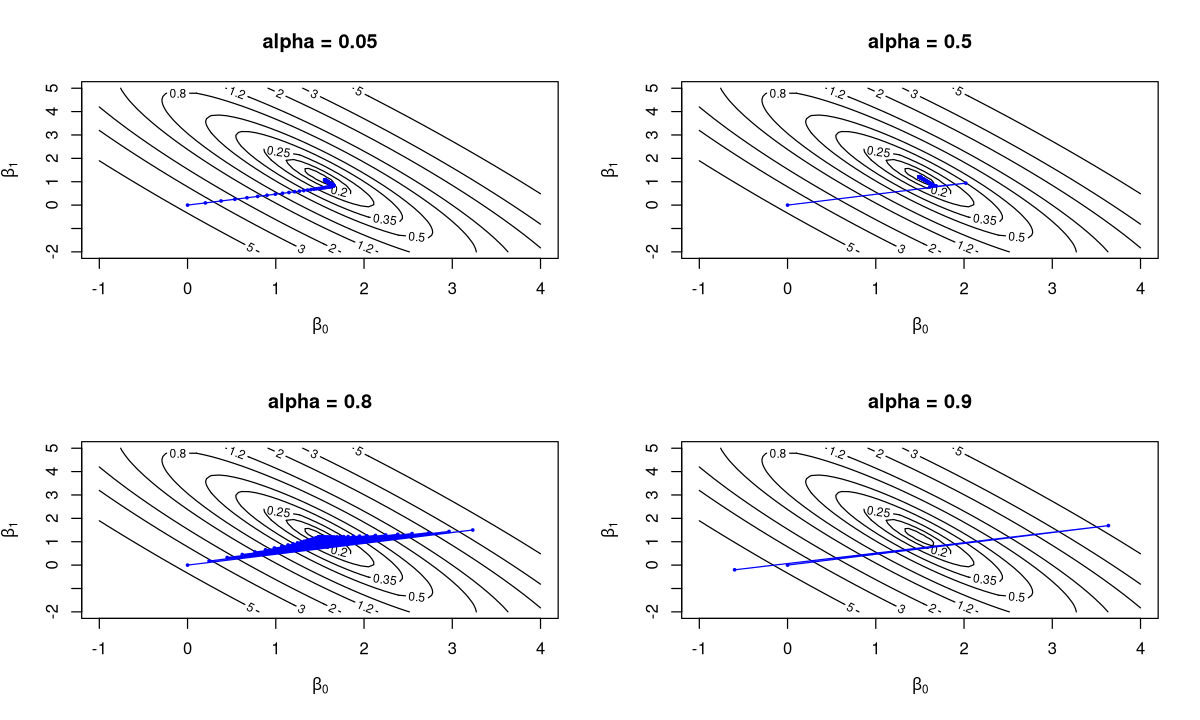

In [13]:
alphas <- c(0.05, 0.5, 0.8, 0.9)
res_alpha <- lapply(alphas, function(a) descente_gradient_2p(xm, ly, alpha = a, n_iter = 300))
names(res_alpha) <- paste("alpha =", alphas)

par(mfrow = c(2, 2))
for (k in seq_along(alphas)) {
  r <- res_alpha[[k]]
  contour(b0_seq, b1_seq, Jmat, levels = niveaux, main = names(res_alpha)[k],
          xlab = expression(beta[0]), ylab = expression(beta[1]))
  ok <- r$chemin[, 1] > -1 & r$chemin[, 1] < 4 & r$chemin[, 2] > -2 & r$chemin[, 2] < 5
  lines(r$chemin[ok, 1], r$chemin[ok, 2], col = "blue", type = "o", pch = 20, cex = 0.5)
}
par(mfrow = c(1, 1))
sapply(res_alpha, function(r) c(iterations = r$iterations, J_final = tail(r$J, 1)))

**Lecture** :

- $\alpha = 0.05$ : le chemin est régulier mais **lent** : après 300 itérations, on n'a pas encore atteint le minimum ;
- $\alpha = 0.5$ : convergence rapide ;
- $\alpha = 0.8$ : l'algorithme fait des **zigzags** (il dépasse le fond de la vallée à chaque pas) mais converge encore, et même plus vite ;
- $\alpha = 0.9$ : **divergence** : $J$ explose (valeurs énormes, ~$10^{64}$ après 300 itérations) et le chemin sort du graphique. Aucune estimation n'est obtenue.

Note la frontière très fine entre « rapide » (0.8) et « divergent » (0.9) : c'est pourquoi on surveille toujours la convergence.

### Exercice 5.4 : trouver le seuil de divergence

En testant plusieurs valeurs de $\alpha$ entre 0.5 et 1 (par exemple `seq(0.5, 1, by = 0.05)`), trouve approximativement la plus grande valeur de $\alpha$ pour laquelle l'algorithme converge encore sur `xm`. Indique pour chacune le nombre d'itérations (max 5000).

In [14]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
for (a in seq(0.5, 1, by = 0.05)) {
  r <- descente_gradient_2p(xm, ly, alpha = a, n_iter = 5000)
  cat("alpha =", a, " itérations =", r$iterations, " J final =", signif(tail(r$J, 1), 4), "\n")
}
```

Le nombre d'itérations diminue quand $\alpha$ augmente (258 pour 0.5, 167 pour 0.8), puis l'algorithme **diverge** brutalement à partir de $\alpha = 0.85$ (J final énorme, `Inf` ou `NaN`) : le seuil se situe vers **0.83** ici. Ce seuil dépend des données : il est lié à la **courbure** maximale de la fonction de coût (plus le bol est « pentu » dans une direction, plus $\alpha$ doit être petit). Il n'existe pas de valeur universelle : on teste et on **surveille la convergence**.

Pour les curieux : la convergence est garantie si $\alpha < 2/\lambda_{max}$, où $\lambda_{max}$ est la plus grande valeur propre de la matrice des dérivées secondes $\frac{2}{n}X'X$ :

```r
H <- 2 / n * crossprod(cbind(1, xm))
2 / max(eigen(H)$values)        # ≈ 0.83
```

</details>

## 5.6 Vérifier la convergence

Le syllabus recommande de **suivre l'évolution de la fonction de coût après chaque itération** pour s'assurer que le calcul converge (Fig. 11) : $J$ doit **diminuer à chaque itération** puis se stabiliser (plateau).

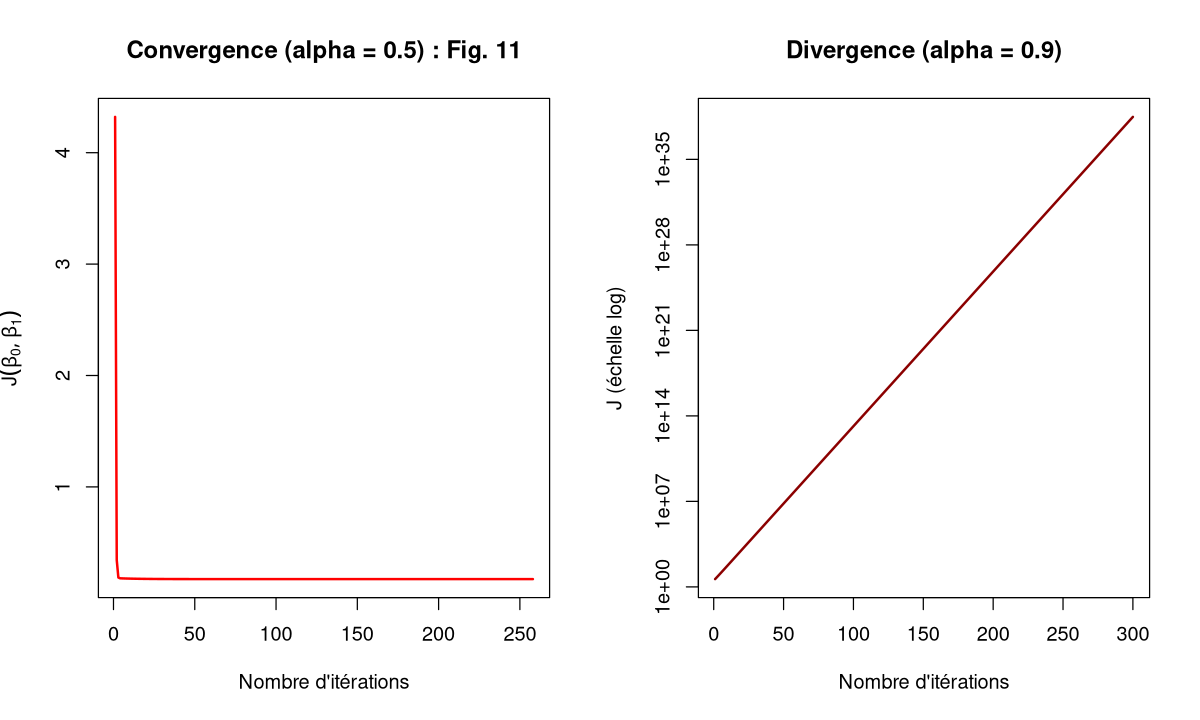

In [15]:
par(mfrow = c(1, 2))
plot(res_alpha[["alpha = 0.5"]]$J, type = "l", lwd = 2, col = "red",
     xlab = "Nombre d'itérations", ylab = expression(J(beta[0], beta[1])),
     main = "Convergence (alpha = 0.5) : Fig. 11")
plot(res_alpha[["alpha = 0.9"]]$J, type = "l", lwd = 2, col = "darkred", log = "y",
     xlab = "Nombre d'itérations", ylab = "J (échelle log)",
     main = "Divergence (alpha = 0.9)")
par(mfrow = c(1, 1))

- Courbe de gauche : décroissance rapide puis **plateau** → convergence. On peut arrêter l'algorithme quand la diminution de $J$ entre deux itérations devient inférieure à une **tolérance** (`tol` dans notre fonction).
- Courbe de droite : $J$ **augmente** → mauvais réglage : il faut diminuer $\alpha$.

> **Attention** : si $J$ augmente ne serait-ce qu'à une itération, la descente de gradient est mal réglée (α trop grand) ou mal programmée (erreur de signe dans le gradient !).

### Exercice 5.5 : vérifier la décroissance de J

Pour le résultat `gd` (α = 0.5), vérifie avec `diff()` que $J$ diminue **à chaque** itération. Combien d'itérations faut-il pour que $J$ soit à moins de 1 % de sa valeur finale ?

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
all(diff(gd$J) <= 0)                          # TRUE : J ne remonte jamais
J_final <- tail(gd$J, 1)
which(gd$J < 1.01 * J_final)[1]               # première itération à moins de 1 % du minimum
```

`diff()` calcule les différences entre éléments successifs : toutes doivent être négatives (ou nulles). On voit que la plus grande partie de la diminution se fait en quelques dizaines d'itérations ; les suivantes servent à « peaufiner » les décimales.

</details>

## 5.7 Mise à l'échelle des variables (feature scaling)

Les variables explicatives ont généralement des **échelles différentes**. Pour **accélérer** l'estimation des coefficients par la descente de gradient, le syllabus recommande de **standardiser** les données (*feature scaling*), pour avoir des valeurs explicatives entre −1 et 1 ou entre −0.5 et 0.5.

Méthodes proposées dans le syllabus :

| Méthode | Formule | Intervalle approximatif |
|---|---|---|
| Diviser par le maximum | $x' = \dfrac{x}{x_{max}}$ | entre −1 et 1 |
| Centrer puis diviser par l'écart-type (**autoscaling**) | $x' = \dfrac{x - \bar x}{s_x}$ | moyenne 0, écart-type 1 |
| Centrer puis diviser par le maximum | $x' = \dfrac{x - \bar x}{x_{max}}$ | |
| Centrer puis diviser par l'étendue | $x' = \dfrac{x - \bar x}{x_{max} - x_{min}}$ | entre −0.5 et 0.5 environ |

(la partie 1 a aussi présenté le **min-max** $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$, entre 0 et 1, utilisé plus haut).

Comparons le nombre d'itérations nécessaires avec `x` **brut**, **min-max** et **autoscalé** :

In [17]:
xs <- (x - mean(x)) / sd(x)            # autoscaling (équivalent à as.vector(scale(x)))

# même taux d'apprentissage pour les trois versions
gd_brut <- descente_gradient_2p(x,  ly, alpha = 0.5, n_iter = 50000)
gd_mm   <- descente_gradient_2p(xm, ly, alpha = 0.5, n_iter = 50000)
gd_auto <- descente_gradient_2p(xs, ly, alpha = 0.5, n_iter = 50000)

data.frame(echelle    = c("brute", "min-max", "autoscaling"),
           iterations = c(gd_brut$iterations, gd_mm$iterations, gd_auto$iterations),
           beta0      = c(gd_brut$coef[1], gd_mm$coef[1], gd_auto$coef[1]),
           beta1      = c(gd_brut$coef[2], gd_mm$coef[2], gd_auto$coef[2]))

echelle,iterations,beta0,beta1
<chr>,<int>,<dbl>,<dbl>
brute,5918,3.150103,6.3730081
min-max,258,1.491977,1.2095603
autoscaling,5,2.020004,0.2622646


Avec le même $\alpha$, il faut près de **6 000 itérations** avec `x` brut, environ 250 avec le min-max et **5** seulement avec l'autoscaling (les coefficients diffèrent car ils sont exprimés à l'échelle de chaque version de `x`). Pourquoi ? Regardons la forme des courbes de niveau :

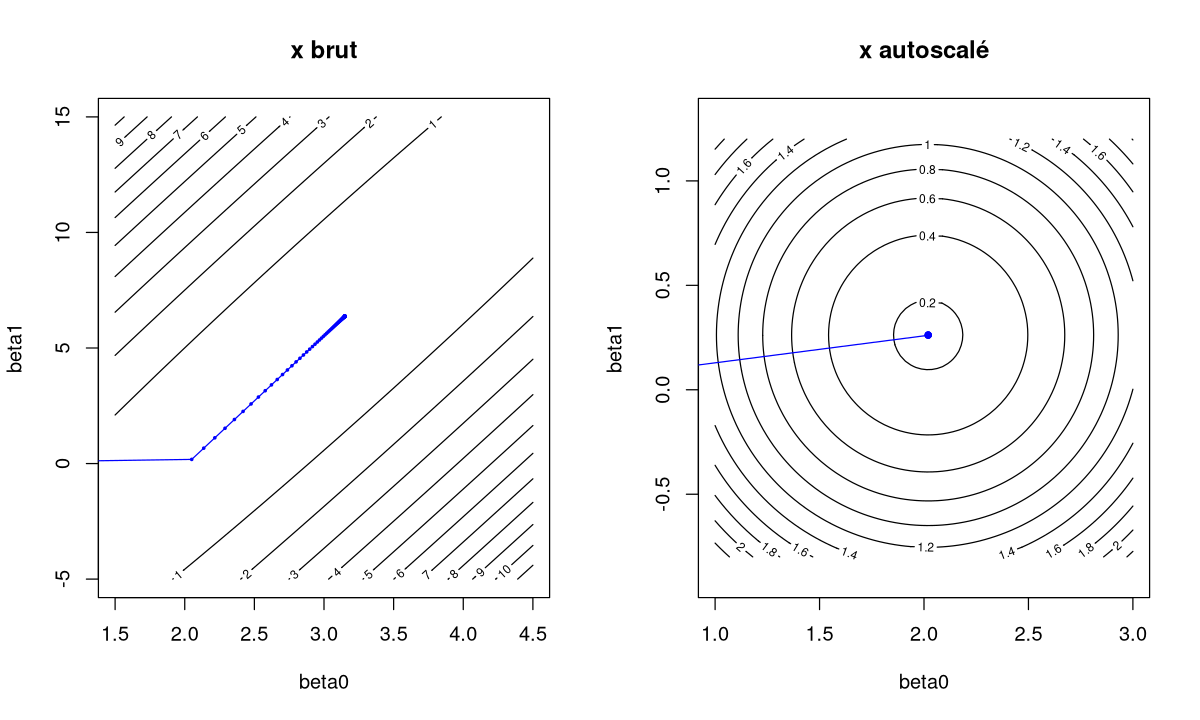

In [18]:
par(mfrow = c(1, 2))
# x brut : bol très allongé (vallée étroite)
b0r <- seq(1.5, 4.5, length.out = 80); b1r <- seq(-5, 15, length.out = 80)
Jr <- outer(b0r, b1r, Vectorize(function(a, b) mean((ly - a - b * x)^2)))
contour(b0r, b1r, Jr, nlevels = 15, main = "x brut", xlab = "beta0", ylab = "beta1")
lines(gd_brut$chemin[seq(1, gd_brut$iterations, by = 50), ], col = "blue", type = "o", pch = 20, cex = 0.4)
# x autoscalé : cercles
b0s <- seq(1, 3, length.out = 80); b1s <- seq(-0.8, 1.2, length.out = 80)
Js <- outer(b0s, b1s, Vectorize(function(a, b) mean((ly - a - b * xs)^2)))
contour(b0s, b1s, Js, nlevels = 15, main = "x autoscalé", xlab = "beta0", ylab = "beta1", asp = 1)
lines(gd_auto$chemin, col = "blue", type = "o", pch = 20)
par(mfrow = c(1, 1))

- Avec `x` brut (écart-type 0.04), la fonction de coût est une **vallée très étroite et allongée** : elle est très pentue dans une direction et presque plate dans l'autre. Le taux $\alpha$ doit rester petit (sinon divergence dans la direction pentue), et on avance alors **très lentement** dans la direction plate.
- Avec `x` autoscalé, les courbes de niveau sont des **cercles** : le gradient pointe directement vers le minimum → quelques itérations suffisent (ici, avec $\alpha = 0.5$, l'algorithme « saute » quasiment directement au minimum).

Les coefficients obtenus sur les données mises à l'échelle se **retransforment** facilement vers l'échelle d'origine. Avec $x_s = (x - \bar x)/s_x$ :

$$\hat y = \beta_0^{s} + \beta_1^{s}\frac{x - \bar x}{s_x} \;\Rightarrow\; \beta_1 = \frac{\beta_1^{s}}{s_x},\qquad \beta_0 = \beta_0^{s} - \beta_1\,\bar x$$

In [19]:
b1_orig <- gd_auto$coef[2] / sd(x)
b0_orig <- gd_auto$coef[1] - b1_orig * mean(x)
rbind(retransformes = c(b0_orig, b1_orig), lm = coef(lm(ly ~ x)))

,(Intercept),x
retransformes,3.150178,6.373433
lm,3.150178,6.373433


> **Complément** : la standardisation est aussi indispensable pour les **régressions pénalisées** (partie 6) et la **régression polynomiale** (partie 3), mais pour une autre raison : donner la même importance (même pénalité, même échelle) à toutes les variables.

### Exercice 5.6 : les autres méthodes de scaling

1. Crée `x_max <- x / max(abs(x))` (division par le maximum en valeur absolue) et `x_range <- (x - mean(x)) / (max(x) - min(x))` (centrage + étendue).
2. Pour chacune, lance `descente_gradient_2p()` avec `alpha = 0.5` (max 50 000 itérations) et compare le nombre d'itérations à celui de l'autoscaling.
3. Laquelle des méthodes est la moins efficace ici ? Pourquoi, d'après toi ?

In [20]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
x_max   <- x / max(abs(x))
x_range <- (x - mean(x)) / (max(x) - min(x))
r_max   <- descente_gradient_2p(x_max,   ly, alpha = 0.5, n_iter = 50000)
r_range <- descente_gradient_2p(x_range, ly, alpha = 0.5, n_iter = 50000)
c(max = r_max$iterations, range = r_range$iterations, auto = gd_auto$iterations)
summary(x_max); sd(x_max)
```

Résultat : ≈ 660 itérations (division par le max), ≈ 240 (centrage + étendue), 5 (autoscaling).

- La division par le maximum ne **centre pas** les données : ici toutes les absorbances sont négatives, donc `x_max` varie entre −1 et −0.27, avec un faible écart-type (0.16) → la vallée reste allongée et inclinée : c'est la moins efficace.
- Le centrage + étendue donne des valeurs centrées entre −0.5 et 0.5 : beaucoup plus rapide, mais l'écart-type (≈ 0.22) reste petit → plus lent que l'autoscaling.
- L'**autoscaling** (moyenne 0, écart-type 1) donne ici le bol le plus « rond » → convergence la plus rapide.

</details>

## 5.8 Généralisation : descente de gradient multivariée

Avec $p$ variables, on écrit le modèle sous forme matricielle $y = X\beta + e$ (avec une colonne de 1 pour l'intercept). La fonction de coût et son **gradient** (vecteur des $p+1$ dérivées partielles) s'écrivent :

$$J(\beta) = \frac{1}{n}(y - X\beta)'(y - X\beta) \qquad \nabla J(\beta) = -\frac{2}{n}X'(y - X\beta)$$

et la mise à jour simultanée de **tous** les coefficients devient une seule ligne :

$$\beta \leftarrow \beta - \alpha\,\nabla J(\beta)$$

Au minimum, $\nabla J = 0 \Leftrightarrow X'X\beta = X'y$ : ce sont les équations normales, dont la solution analytique est $\hat\beta = (X'X)^{-1}X'y$ (partie 3). La descente de gradient y arrive **sans inverser de matrice**.

In [21]:
gradient_descent <- function(X, y, alpha = 0.1, n_iter = 10000, tol = 1e-12, b_init = NULL) {
  X <- cbind(Intercept = 1, as.matrix(X))      # ajoute la colonne de 1
  n <- nrow(X)
  b <- if (is.null(b_init)) rep(0, ncol(X)) else b_init
  J <- numeric(n_iter)
  for (i in 1:n_iter) {
    r <- y - X %*% b                           # résidus
    J[i] <- mean(r^2)                          # fonction de coût
    grad <- -2 / n * crossprod(X, r)           # gradient = -(2/n) X'(y - Xb)
    b <- b - alpha * grad                      # mise à jour simultanée de tous les coefficients
    if (!is.finite(J[i])) break
    if (i > 1 && abs(J[i - 1] - J[i]) < tol) break
  }
  b <- drop(b); names(b) <- colnames(X)
  list(coef = b, J = J[1:i], iterations = i)
}

# Test sur le cas univarié autoscalé : doit redonner gd_auto
gradient_descent(xs, ly, alpha = 0.5)$coef

Intercept           
2.0200037 0.2622646

> **Fonction maison** : `gradient_descent(X, y, alpha, n_iter, tol, b_init)`
>
> | Argument | Rôle |
> |---|---|
> | `X` | matrice (ou vecteur) des variables explicatives, **sans** colonne de 1 (ajoutée automatiquement) ; à **standardiser** au préalable |
> | `y` | variable réponse |
> | `alpha` | taux d'apprentissage |
> | `n_iter` | nombre maximal d'itérations |
> | `tol` | arrêt si $J$ diminue de moins de `tol` entre deux itérations |
> | `b_init` | valeurs initiales (par défaut 0) |
>
> Renvoie la liste `coef` (coefficients), `J` (historique du coût), `iterations`.
>
> **Fonctions R utilisées** : `cbind()` (coller des colonnes), `%*%` (produit matriciel), `crossprod(X, r)` (= `t(X) %*% r`, plus rapide), `drop()` (matrice 1 colonne → vecteur).

### Application : les 10 features les plus corrélées

On reprend les 10 points spectraux de la partie 3, **autoscalés** avec `scale()`.

In [22]:
correlation <- cor(lactoferrin[, 2:1061], lactoferrin$V1062)[, 1]
ordercorrelation <- order(abs(correlation))
X10 <- scale(as.matrix(lactoferrin[, ordercorrelation[1051:1060] + 1]))   # autoscaling des 10 features

gd10 <- gradient_descent(X10, ly, alpha = 0.1, n_iter = 20000)
lm10 <- lm(ly ~ X10)
gd10$iterations
round(rbind(descente_gradient = gd10$coef, lm = coef(lm10)), 3)
c(J_descente = tail(gd10$J, 1), J_lm = mean(resid(lm10)^2))

[1] 20000

,Intercept,V608,V679,V716,V710,V209,V715,V711,V714,V712,V713
descente_gradient,2.02,-0.031,-0.053,0.327,0.608,0.020,-0.975,-1.342,0.110,0.188,1.337
lm,2.02,-0.030,-0.039,-1.796,-0.751,0.026,7.823,5.294,-17.744,-16.114,23.598


J_descente       J_lm 
 0.1455374  0.1443126

**Surprise !** Après 20 000 itérations (le maximum autorisé : la tolérance n'est pas atteinte), la valeur de la fonction de coût est **très proche** de celle de `lm()` (moins de 1 % d'écart), mais **les coefficients sont très différents** (sauf l'intercept).

L'explication est la **colinéarité** (partie 3) : les points spectraux voisins sont corrélés à plus de 0.9. Il existe alors une infinité de combinaisons de coefficients qui donnent presque la même erreur : la fonction de coût a une **vallée quasi plate** dans certaines directions. La descente de gradient y avance extrêmement lentement, et la solution exacte de `lm()` repose sur l'inversion d'une matrice $X'X$ **presque singulière** (coefficients énormes et de signes opposés, non significatifs).

[1] 1.500951e-04 1.173986e+03

[1] 7821615

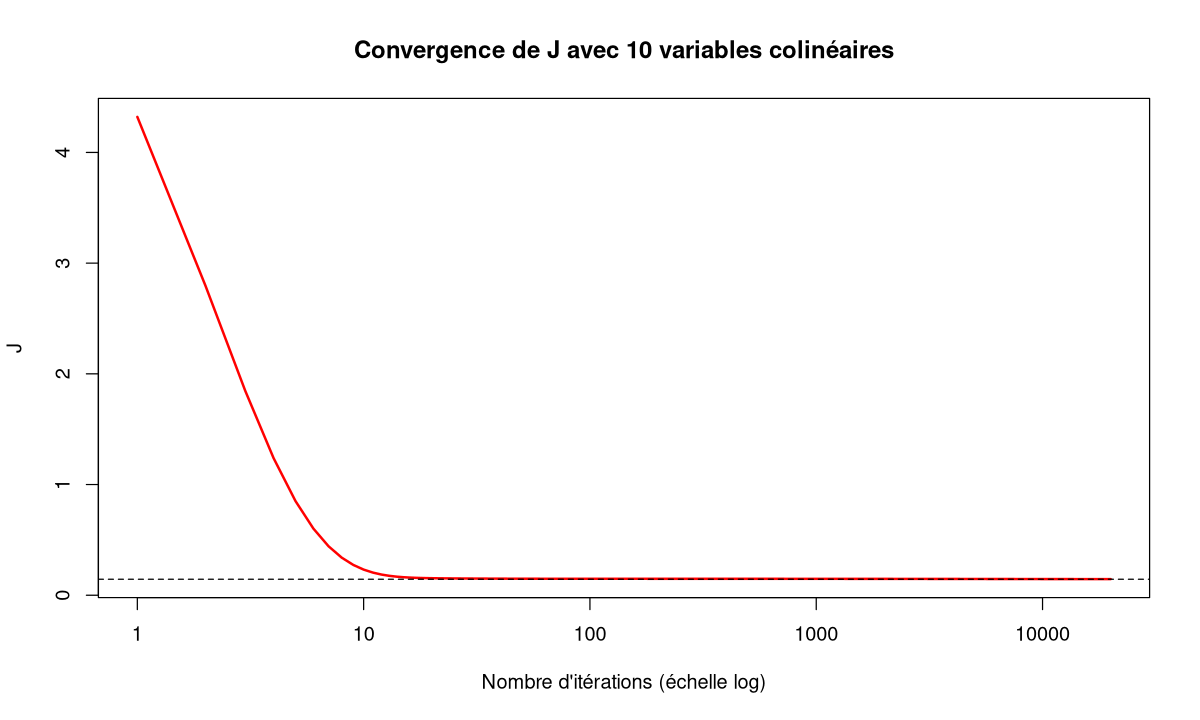

In [23]:
# Mesure de la colinéarité : rapport entre plus grande et plus petite valeur propre de X'X
vp <- eigen(crossprod(cbind(1, X10)))$values
range(vp)
max(vp) / min(vp)          # nombre de conditionnement : énorme = matrice presque singulière

plot(gd10$J, type = "l", log = "x", lwd = 2, col = "red",
     xlab = "Nombre d'itérations (échelle log)", ylab = "J",
     main = "Convergence de J avec 10 variables colinéaires")
abline(h = mean(resid(lm10)^2), lty = 2)

**À retenir** : même avec des données standardisées, la colinéarité rend l'estimation des coefficients **instable** (méthode analytique) ou **très lente** (méthode itérative). Deux solutions du cours :

- **sélectionner** des variables (partie 4) ;
- **pénaliser** les coefficients (Ridge, Lasso : partie 6) : la pénalité « relève » le fond plat de la vallée et rend le minimum unique et bien défini.

### Exercice 5.7 : descente de gradient sur un modèle sélectionné

La sélection backward de la partie 4 a retenu 5 variables : V715, V711, V714, V712, V713 (colonnes 6 à 10 de `X10`).

1. Applique `gradient_descent()` sur `X10[, 6:10]` avec `alpha = 0.1` et 50 000 itérations maximum.
2. Compare les coefficients à ceux de `lm(ly ~ X10[, 6:10])`. Les deux méthodes s'accordent-elles mieux qu'avec 10 variables ?
3. Trace l'évolution de J.

In [24]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
gd5 <- gradient_descent(X10[, 6:10], ly, alpha = 0.1, n_iter = 50000)
lm5 <- lm(ly ~ X10[, 6:10])
gd5$iterations
round(rbind(descente = gd5$coef, lm = coef(lm5)), 3)
plot(gd5$J, type = "l", log = "x", xlab = "Itérations", ylab = "J")
```

**Non** : même après 50 000 itérations (non convergé), les coefficients restent très différents de ceux de `lm()` (par ex. V713 : ≈ 2.1 contre ≈ 14.2), alors que J est presque identique. Les 5 variables sont des points spectraux **adjacents** (V711 à V715), corrélés à plus de 0.9 entre eux : la vallée plate demeure. La sélection réduit le nombre de variables mais **ne supprime pas la colinéarité** ; c'est l'une des motivations des régressions pénalisées (partie 6) et des méthodes de réduction de dimension (PCR, PLS : module 2).

</details>

## 5.9 Complément : `optim()`

R dispose d'un optimiseur généraliste, `optim()`, qui minimise **n'importe quelle** fonction de coût. On lui donne la fonction à minimiser, des valeurs initiales et (facultatif) le gradient. Les algorithmes proposés (`"BFGS"`, `"CG"`, `"L-BFGS-B"`…) sont des variantes perfectionnées de la descente de gradient (ils adaptent la taille des pas automatiquement).

In [25]:
cout <- function(b) mean((ly - b[1] - b[2] * x)^2)                       # J(beta0, beta1), x BRUT
gradient <- function(b) { r <- ly - b[1] - b[2] * x; c(-2 * mean(r), -2 * mean(x * r)) }

opt <- optim(par = c(0, 0), fn = cout, gr = gradient, method = "BFGS")
opt$par           # coefficients estimés
opt$counts        # nombre d'évaluations de la fonction et du gradient
opt$convergence   # 0 = convergence réussie

[1] 3.150171 6.373396

function gradient 
      12        8

[1] 0

Même avec `x` brut, `optim()` converge en quelques dizaines d'évaluations, là où notre descente de gradient « simple » en demandait des milliers. Le principe reste le même : **minimiser une fonction de coût en suivant sa pente**. Ce sera utile pour les modèles sans solution analytique (régression logistique, réseaux de neurones).

> **Fonction R** : `optim(par, fn, gr = NULL, method = "Nelder-Mead", control = list())`
>
> | Argument | Rôle |
> |---|---|
> | `par` | valeurs initiales des paramètres |
> | `fn` | fonction à **minimiser** (prend un vecteur de paramètres, renvoie un nombre) |
> | `gr` | fonction gradient (facultatif ; sinon approximée numériquement) |
> | `method` | `"Nelder-Mead"` (défaut, sans gradient), `"BFGS"`, `"CG"`, `"L-BFGS-B"` (avec bornes)… |
> | `control` | ex. `list(maxit = 1000)` |
>
> Renvoie `$par` (optimum), `$value` (valeur de `fn` à l'optimum), `$counts`, `$convergence` (0 = OK).

### Exercice 5.8 : régression sans intercept avec `optim()`

Avec `optim()` (méthode `"BFGS"`), estime $\beta_1$ dans le modèle sans intercept $y_c = \beta_1 x_c$ sur les données centrées de la section 5.2. Compare au résultat de la formule $\sum x_c y_c / \sum x_c^2$.
*Indice : avec un seul paramètre, Nelder-Mead n'est pas recommandé ; utilise `method = "BFGS"`.*

In [26]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
opt1 <- optim(par = 0, fn = J1, method = "BFGS")
c(optim = opt1$par, formule = b1_formule)
```

On réutilise directement la fonction de coût `J1` définie en 5.2. Les deux résultats coïncident (≈ 6.373).

</details>

### Questions de compréhension (vrai/faux)

1. La descente de gradient donne toujours exactement la même solution que $(X'X)^{-1}X'y$.
2. Si $J$ augmente au fil des itérations, il faut augmenter $\alpha$.
3. Près du minimum, les pas de l'algorithme sont plus petits même si $\alpha$ est constant.
4. Standardiser les variables change la valeur minimale de $J$.
5. Les valeurs initiales influencent le nombre d'itérations mais pas le minimum atteint pour une régression linéaire.

<details>
<summary><b>Voir les réponses</b></summary>

1. **Faux** : elle s'en approche avec une précision qui dépend de la tolérance et du nombre d'itérations ; avec des variables colinéaires, elle peut rester loin en termes de coefficients (section 5.8).
2. **Faux** : il faut **diminuer** $\alpha$ (pas trop grands → divergence).
3. **Vrai** : le pas vaut $\alpha \times$ gradient, et le gradient tend vers 0 au minimum.
4. **Faux** : une transformation linéaire de x ne change pas les prédictions optimales, donc pas le minimum de $J$ ; seules la forme du « bol » et la valeur des coefficients changent.
5. **Vrai** : la fonction de coût est convexe (un seul minimum).

</details>

## Récapitulatif

**Points clés**

- Les coefficients d'une régression peuvent être obtenus **analytiquement** ($\hat\beta = (X'X)^{-1}X'y$) ou **numériquement** en minimisant la **fonction de coût** $J(\beta) = \frac{1}{n}\sum(y_i - \hat y_i)^2$.
- Avec 1 paramètre, $J$ est une parabole ; avec 2, une surface en bol (représentée par des **courbes de niveau**).
- **Descente de gradient** : $\beta_j \leftarrow \beta_j - \alpha\,\dfrac{\partial J}{\partial\beta_j}$, avec mise à jour **simultanée** de tous les coefficients ; forme matricielle $\beta \leftarrow \beta + \alpha\frac{2}{n}X'(y - X\beta)$.
- Le **sens** du pas dépend du signe de la dérivée ; sa **taille** diminue près du minimum (pente plus faible) → $\alpha$ peut rester constant.
- **Taux d'apprentissage** $\alpha$ : trop petit = lent, trop grand = zigzags puis **divergence**.
- **Vérifier la convergence** : $J$ doit diminuer à chaque itération puis atteindre un plateau.
- **Feature scaling** (autoscaling, min-max, division par le max, centrage + étendue) : rend le bol plus « rond » → convergence beaucoup plus rapide.
- La **colinéarité** crée des vallées plates : convergence très lente et coefficients instables → sélection (partie 4) ou pénalisation (partie 6).

**Fonctions R vues**

| Fonction | Usage |
|---|---|
| `sapply(grille, f)` | évaluer une fonction sur une grille de valeurs |
| `outer(a, b, Vectorize(f))` | évaluer une fonction de 2 variables sur une grille → matrice |
| `persp()`, `contour()`, `filled.contour()` | surface 3D, courbes de niveau |
| `abline(a, b)` | tracer une tangente / une droite |
| `scale()` | autoscaling (centrer-réduire) des colonnes d'une matrice |
| `%*%`, `crossprod()`, `cbind()`, `drop()` | calcul matriciel du gradient |
| `diff()` | vérifier la décroissance de $J$ |
| `eigen()` | valeurs propres (diagnostic de colinéarité) |
| `optim()` | optimiseur généraliste (BFGS…) |
| `descente_gradient_2p()`, `gradient_descent()` | fonctions maison écrites dans ce notebook |

**Partie suivante** : `06_Regressions_penalisees.ipynb` : ajouter une **pénalité** à la fonction de coût (Ridge, Lasso, Elastic Net).